# Simulating a scanning-3DXRD dataset

`python -m anri.render` simulates a scanning-3DXRD dataset from a map, as ImageD11 files that ImageD11 and `python -m anri.index` read. It runs in three stages, each writing one file that the next one reads:

| Stage | What it does | Options | What the plots show |
|---|---|---|---|
| `prepare` | map entries per phase, reflections and structure factors, the beam's spreads, the scan's motor positions | `--optics`, `--bandwidth`, `--beam-fwhm`, `--dty-step`, `--margin`, `--omega-step`, `--tth-max`, `--density`, `--cif` | the sample against the rows' reach; each ring's share of the detector |
| `render` | rows of the scan rendered into sparse pixels above the segmentation cut; rows can be split between jobs (`--rows a:b`) | `--cut`, `--window`, `--max-frames` | counts per pixel and what the cut keeps; how much of each peak its window holds |
| `assemble` | the rendered rows gathered into an ImageD11 dataset (`_sparse.h5`, `pars/`, the DataSet) | `--peaks-table` | a rendered row, summed over its frames |

This notebook runs the same stages, with the plots that help choose each option (`anri.render.diagnostics` and `anri.render.plots`). The files it writes are the command line's, with the same provenance, and it ends with the `python -m anri.render run` command that remakes them.

By default it renders the [AM-like 316L phantom](phantom.ipynb) shipped in `tests/data/phantoms/am316l` (38 grains with misoriented cells and twin lamellae, 0.5 µm voxels), on an Eiger 4M at 43.6 keV with ID11's Al CRLs: 57 rows of 1 µm, 1800 frames of 0.1°. The render takes about two minutes on a GPU, so this notebook is stored with its outputs and not re-run when the docs are built. With `interactive = True` (the default when you run it), sliders redraw the plots, and **the value on a slider is what the later cells use**; it needs `ipywidgets`, `ipympl` and `matplotlib`.

In [1]:
# Parameters: the options of python -m anri.render. The sliders below start from these values.

map_file = None  # an ImageD11 TensorMap (.h5) or python -m anri.index's _entries.npz; None: the AM316L phantom
pars_file = None  # ImageD11 geometry (.par or pars.json); None: the Eiger 4M geometry below
cif = None  # --cif: one path, or {phase name: path} (None: |F|^2 = 1)
# instrument
optics = "al-crl"  # --optics: "al-crl" or "si-nanolens" (ID11's focusing optics: the beam's convergence)
divergence = None  # --divergence: the convergence's sigma (rad) instead of the optics'
bandwidth = 2e-3  # --bandwidth: FWHM of dlambda/lambda (ID11's Laue monochromator)
beam_fwhm = None  # --beam-fwhm (None: the dty step)
psf = 0.5  # --psf: detector point spread (sigma, pixels)
det_shape = (2162, 2068)  # --det-shape: an Eiger 4M
# scan
y0 = 0.0  # --y0
omega_range = (0.0, 180.0)  # --omega-range
omega_step = 0.1  # --omega-step
dty_step = 1.0  # --dty-step (None: the map's voxel size)
margin = 3.0  # --margin: rows cover the sample and this many beam FWHM either side
tth_max = None  # --tth-max (None: the largest ring wholly on the detector)
density = 30.0  # --density: counts per unit density
# rendering
cut = 1.0  # --cut: keep counts above this, as ImageD11's segmentation
window = (3, 7, 7)  # --window: frames, slow, fast
max_frames = 31  # --max-frames

analysisroot = None  # where the ImageD11 dataset goes (None: a temporary folder)
sample, dataset = "am316l", "sim"
outdir = None  # where the stage files go (None: analysisroot)
n_cpu = 4  # --n-cpu

# this notebook only
interactive = True  # sliders (ipympl); False: static figures at the parameters' values, as stored in the docs
probe = None  # rows rendered to look at counts and windows (None: the middle row and one through the sample's edge)

In [2]:
import anri.utils

anri.utils.setup(n_cpu=n_cpu)  # before any JAX computation

import os
import tempfile
import time
from types import SimpleNamespace

import ipywidgets as widgets
import numpy as np
from IPython import get_ipython
from IPython.display import display
from matplotlib import pyplot as plt

import anri.io
import anri.render as rd
from anri.render import diagnostics as dg
from anri.render import plots as pl

get_ipython().run_line_magic("matplotlib", "widget" if interactive else "inline")
T0 = time.time()
NOTEBOOK = "rendering_parameters.ipynb"  # recorded as the command in each stage file's provenance


def log(msg):
    print(f"[{time.time() - T0:7.1f} s] {msg}", flush=True)


def figure(name, **kwargs):
    plt.close(name)
    with plt.ioff():
        fig = plt.figure(name, layout="constrained", **kwargs)
    if interactive:
        fig.canvas.header_visible = False
    return fig


def show(fig):
    display(fig.canvas if interactive else fig)


def interact(fig, update, **controls):
    # sliders that call a plot's update, which redraws it and returns a summary; their values are in .kwargs
    if not interactive:  # draw once at the controls' starting values
        values = {k: c.value for k, c in controls.items()}
        print(update(**values))
        display(fig)
        return SimpleNamespace(kwargs=values)
    w = widgets.interactive(lambda **kw: print(update(**kw)), **controls)
    display(w, fig.canvas)
    return w


def slider(value, lo, hi, step, name):
    return widgets.FloatSlider(value=value, min=lo, max=hi, step=step, description=name, continuous_update=False,
                               readout_format=".3g")

## The map and the geometry

The map is an ImageD11 `TensorMap` (every phase in it is rendered; each needs a space-group number) or the populations the indexer writes (`_entries.npz`), so a map indexed from data can be rendered back and compared with the data. The geometry is an ImageD11 `.par` file (or `pars.json`); for the phantom, an Eiger 4M 150 mm from the sample at 43.6 keV.

In [3]:
if map_file is None:
    map_file = os.path.join("..", "..", "..", "tests", "data", "phantoms", "am316l", "am316l_tmap.h5")
if analysisroot is None:
    analysisroot = tempfile.mkdtemp()
outdir = outdir or analysisroot
if pars_file is None:
    pars_file = os.path.join(outdir, "geometry.par")
    anri.io.write_par(pars_file, {
        "y_center": 1049.9, "y_size": 75.0, "tilt_y": 0.0, "z_center": 1116.5, "z_size": 75.0, "tilt_z": 0.0,
        "tilt_x": 0.0, "distance": 150e3, "o11": -1, "o12": 0, "o21": 0, "o22": -1, "wavelength": 0.2843,
        "wedge": 0.0, "chi": 0.0,
    })
stem = os.path.join(outdir, os.path.splitext(os.path.basename(map_file))[0])
prepare_options = {"cif": cif, "optics": optics, "divergence": divergence, "bandwidth": bandwidth,
                   "beam_fwhm": beam_fwhm, "psf": psf, "y0": y0, "omega_range": omega_range, "omega_step": omega_step,
                   "dty_step": dty_step, "margin": margin, "density": density, "det_shape": det_shape,
                   "tth_max": tth_max}


def prepare(**changed):
    prepare_options.update(changed)
    return rd.stage_prepare(map_file, pars_file, f"{stem}_prepare.h5", **prepare_options, command=NOTEBOOK, log=log)


prepare_file = prepare()
p = rd.load_prepare(prepare_file)

[    2.2 s] map ../../../tests/data/phantoms/am316l/am316l_tmap.h5: 1 phase(s), voxel 0.5, sample radius 25; scan 57 rows of 1 x 1800 frames of 0.1 deg; beam FWHM 1, convergence 8e-05 rad (al-crl), bandwidth 0.002 FWHM; 2theta up to 26.75 deg


[    2.5 s] phase 316L: 7845 entries, 180 reflections, |F|^2 = 1


[    2.5 s] -> /tmp/tmpe0r6bylk/am316l_tmap_prepare.h5


## 1. The scan: `--dty-step`, `--margin`, `--beam-fwhm`

The rows run across the sample in steps of `dty_step` (usually the beam's FWHM at ID11), and reach `margin` beam widths beyond it on either side, so that the sample's edge is seen with the whole beam profile. Every voxel should lie inside the red circle: the radius the rows reach at every ω. Fewer, wider rows render faster but blur the sample across dty, as a wider beam would.

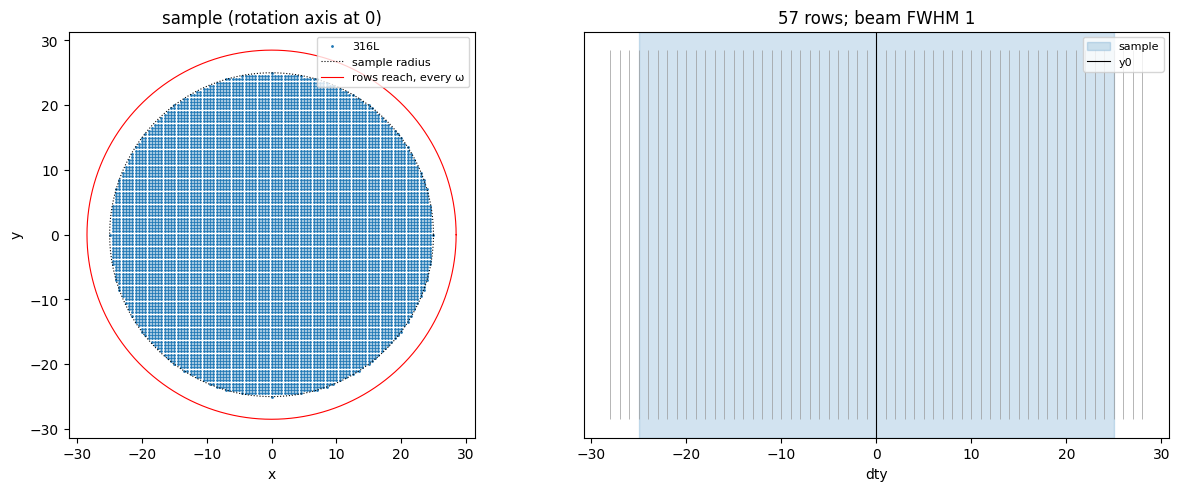

In [4]:
fig = figure("footprint", figsize=(12, 4.8))
pl.plot_footprint(fig, dg.footprint(p))
show(fig)

## 2. Reflections: `--tth-max`

Spots on a ring that runs off the detector are lost wherever they leave it, which an indexer cannot tell from a weak reflection. By default the reflections stop at the largest ring wholly on the detector (top: the fraction of each ring on it, traced from the sample). Lower `tth_max` to render fewer, faster; the rings are re-prepared below if it moves.

tth_max 26.75 deg: reflections 316L: 180; 100% of the outermost ring on the detector


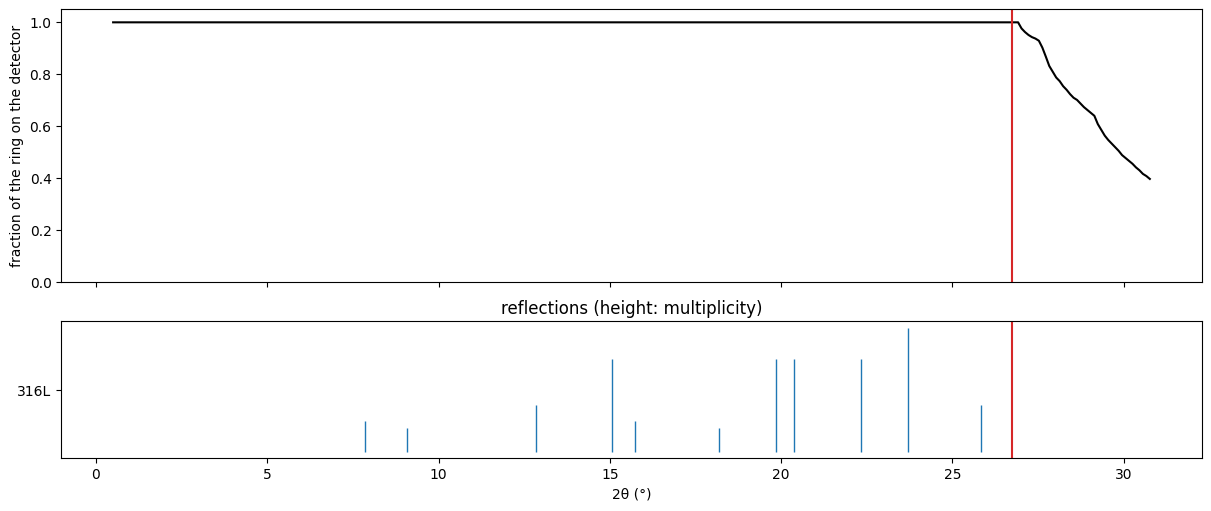

In [5]:
cov = dg.ring_coverage(p)
fig = figure("rings", figsize=(12, 5))
w_tth = interact(fig, pl.plot_rings(fig, cov), tth_max=slider(cov["tth_max"], 2.0, float(cov["tth"][-1]), 0.05,
                                                                "tth_max"))

In [6]:
if not np.isclose(w_tth.kwargs["tth_max"], cov["tth_max"]):
    prepare_file = prepare(tth_max=w_tth.kwargs["tth_max"])
    p = rd.load_prepare(prepare_file)
print(f"tth_max {p['prov']['resolved']['tth_max']:.2f} deg; reflections per phase: "
      + ", ".join(f"{n}: {len(h)}" for n, (_, h, _) in zip(p["names"], p["phases"])))

tth_max 26.75 deg; reflections per phase: 316L: 180


## 3. Counts and the cut: `--density`, `--cut`

ImageD11's segmentation keeps only pixels above a cut, so the faint ends and tails of a peak are missing from real data; the renderer applies the same cut. A few rows are rendered here without writing them: the middle row and one through the sample's edge. The intensities scale with `density` (counts per unit density, i.e. per voxel of full density), so these rows show any density: raise it until the peaks hold enough counts above the cut that their shape survives (right: the share of pixels and of intensity kept against the cut). The rendered values are rounded to integer counts before the cut, as a detector counts.

**Windows** (`--window`, `--max-frames`): each peak is rendered into a window of frames and pixels around it, so the share of a peak left outside its window is lost. Peaks broad in ω (near η = 0 and 180°, or with an orientation spread) get windows of more frames, up to `max_frames`. The plot shows, for each peak centred in the scan, the share of its profile within the scan's ω range that its window misses: what a scan loses at its own ends is not counted against the window. Peaks centred just beyond the ends (the selection reaches as far as the widest window, so a broad one there can still reach the scan) are counted separately; their Friedel mates, 180° away, are in the scan. On the phantom, the dozen peaks that lose ~10% are the broadest, in the widest window: `max_frames = 63` holds them all to within 0.4%, at some cost in time.

[   49.5 s] row 28: 184843 peaks, 555206 pixels (45.5 s)


[   57.8 s] row 48: 117805 peaks, 353964 pixels (8.2 s)


density 30, cut 1: 174037 of 909170 rendered pixels kept (19.1%), holding 93.3% of the intensity; brightest pixel 647 counts (rows [28, 48])


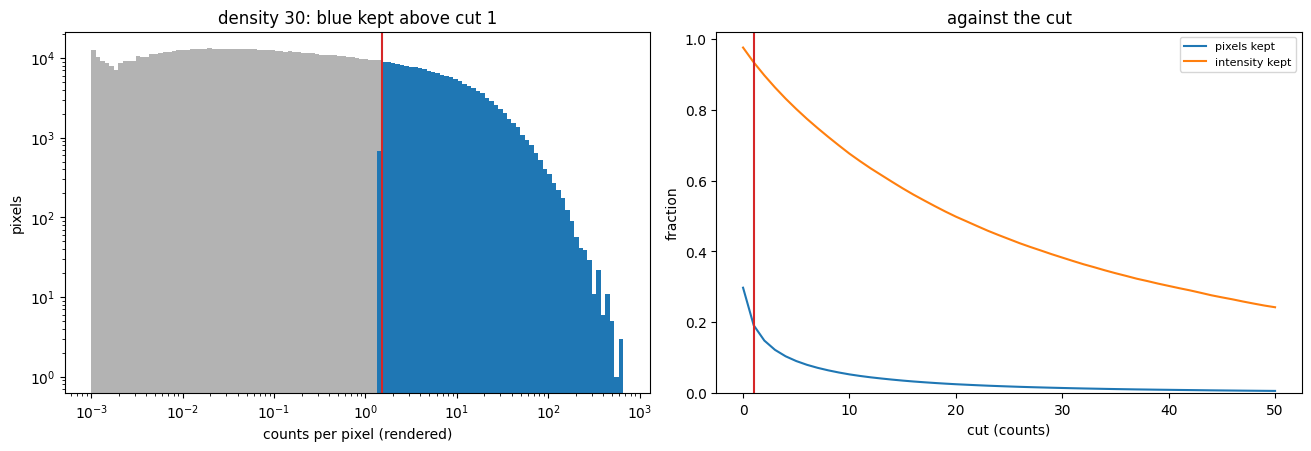

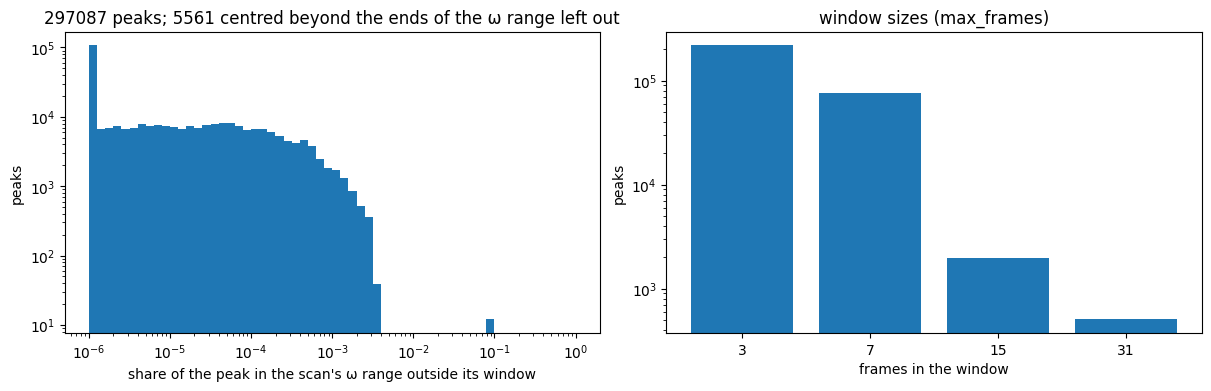

In [7]:
if probe is None:
    mid = p["omega"].shape[0] // 2
    edge = int(np.argmin(np.abs(p["dty"][:, 0] - (p["prov"]["options"]["y0"] + 0.8 * p["prov"]["resolved"]["sample_radius"]))))
    probe = [mid, edge]
probed = dg.probe_rows(p, probe, window, max_frames, log=log)
fig = figure("counts", figsize=(13, 4.4))
w_counts = interact(fig, pl.plot_counts(fig, probed), density=widgets.FloatLogSlider(
    value=p["prov"]["options"]["density"], base=10, min=-1, max=4, step=0.05, description="density",
    continuous_update=False), cut=slider(cut, 0.0, 50.0, 1.0, "cut"))
fig = figure("capture", figsize=(12, 3.8))
pl.plot_capture(fig, probed)
show(fig)

In [8]:
density_used, cut_used = w_counts.kwargs["density"], w_counts.kwargs["cut"]
if not np.isclose(density_used, p["prov"]["options"]["density"]):
    prepare_file = prepare(density=density_used)
    p = rd.load_prepare(prepare_file)
print(f"density {density_used:g}, cut {cut_used:g}")

density 30, cut 1


## 4. Render and assemble

Every row of the scan, every phase summed, written above the cut. Rows are independent: on a cluster, split them between jobs with `python -m anri.render render <prepare file> --rows a:b` (one file per job), then `assemble` gathers every part made from the prepare file, and refuses if a row is missing or twice. Here it is one job.

In [9]:
render_file = rd.stage_render(prepare_file, cut=cut_used, window=window, max_frames=max_frames, command=NOTEBOOK,
                              log=log)
assemble_file = rd.stage_assemble(prepare_file, analysisroot, sample, dataset, command=NOTEBOOK, log=log)

[   59.5 s] rendering rows 0..56 of 57, 1 phase(s)


[   59.5 s] row 0 (dty -28): 0 peaks (0 outside the omega range), 0 pixels above 1, window capture >= 1.0000 (0.0 s)


[   76.1 s] row 1 (dty -27): 5436 peaks (37 outside the omega range), 0 pixels above 1, window capture >= 0.9979 (16.6 s)


[   93.0 s] row 2 (dty -26): 16831 peaks (148 outside the omega range), 68 pixels above 1, window capture >= 0.9972 (16.9 s)


[   93.3 s] row 3 (dty -25): 31599 peaks (331 outside the omega range), 12378 pixels above 1, window capture >= 0.9970 (0.3 s)


...

[  118.9 s] row 55 (dty 27): 5444 peaks (57 outside the omega range), 0 pixels above 1, window capture >= 0.9303 (0.2 s)


[  118.9 s] row 56 (dty 28): 0 peaks (0 outside the omega range), 0 pixels above 1, window capture >= 1.0000 (0.0 s)


[  118.9 s] -> /tmp/tmpe0r6bylk/am316l_tmap_render.h5 (59 s)


[  119.0 s] 1 part(s), 57 rows, 4407877 pixels -> /tmp/tmpe0r6bylk/am316l/am316l_sim/am316l_sim_sparse.h5, /tmp/tmpe0r6bylk/am316l/am316l_sim/am316l_sim_dataset.h5, /tmp/tmpe0r6bylk/pars/pars.json


[  119.0 s] -> /tmp/tmpe0r6bylk/am316l_tmap_assemble.h5


The middle row of the dataset written, summed over its frames (the Debye-Scherrer rings of spots), and the counts per frame.

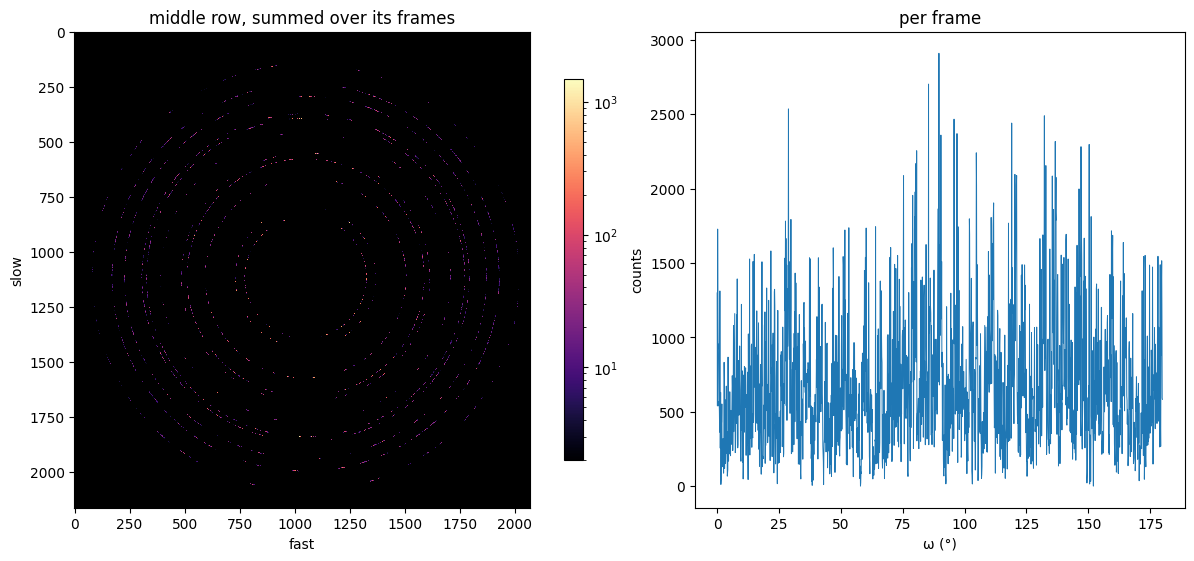

In [10]:
sparse_file = anri.io.read_provenance(assemble_file)["resolved"]["sparse_file"]
fig = figure("row", figsize=(13, 5.5))
pl.plot_row_image(fig, dg.row_image(sparse_file, p["omega"].shape[0] // 2), "middle row, summed over its frames")
show(fig)

## The command line, and the files

The `python -m anri.render run` command that remakes the dataset with every option chosen (`anri.render.run_command`), then how the assemble file was made (`anri.io.show`, as `python -m anri.render show`). The dataset can go straight to the [indexing parameters](indexing_parameters.ipynb) notebook (`analysisroot`, `sample`, `dataset`) or to `python -m anri.index`.

In [11]:
print(rd.run_command(assemble_file), end="\n\n")
print(anri.io.show(assemble_file))

python -m anri.render run /home/esrf/james1997a/Code/Anri/tests/data/phantoms/am316l/am316l_tmap.h5 /tmp/tmpe0r6bylk/geometry.par /tmp/tmpe0r6bylk am316l sim --bandwidth 0.002 --density 30.0 --det-shape 2162 2068 --dty-step 1.0 --margin 3.0 --omega-range 0.0 180.0 --omega-step 0.1 --optics al-crl --pol-factor 1.0 --psf 0.5 --y0 0.0 --batch 65536 --cut 1.0 --max-frames 31 --window 3 7 7

[prepare]
file = '/tmp/tmpe0r6bylk/am316l_tmap_prepare.h5'
anri_version = '0.1.0'
command = 'rendering_parameters.ipynb'
cwd = '/home/esrf/james1997a/Code/Anri/docs/source/tutorials'
date = '2026-10-12T15:52:44+02:00'
git_commit = '1c124b0f1cab01d1ce50e75e7e29f83c37dd9e10'
git_dirty = True
id = '8cd5e99a7a244be59116655280777ae2'

[prepare.options]
bandwidth = 0.002
density = 30.0
det_shape = [2162, 2068]
dty_step = 1.0
map = '/home/esrf/james1997a/Code/Anri/tests/data/phantoms/am316l/am316l_tmap.h5'
margin = 3.0
omega_range = [0.0, 180.0]
omega_step = 0.1
optics = 'al-crl'
pars = '/tmp/tmpe0r6bylk/geome